<!--

    Gaia Data Processing and Analysis Consortium (DPAC) 
    Co-ordination Unit 9 Work Package 930
    
    (c) 2005-2025 Gaia DPAC
    
    This program is free software: you can redistribute it and/or modify
    it under the terms of the GNU General Public License as published by
    the Free Software Foundation, either version 3 of the License, or
    (at your option) any later version.

    This program is distributed in the hope that it will be useful,
    but WITHOUT ANY WARRANTY; without even the implied warranty of
    MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
    GNU General Public License for more details.

    You should have received a copy of the GNU General Public License
    along with this program.  If not, see <https://www.gnu.org/licenses/>.
    -->
    
This notebook illustrates a simple usage of cross-matched survey data available on the platform. It uses Gaia catalogue data (parallaxes and optical photometry) along with cross-matched infrared photometry to plot a de-reddened optical/infrared colour-absolute magnitude diagram (CAMD, a.k.a. an observational Hertzsprung-Russell diagram) of all sources with appropriate measurements.

Please note:
* only PanSTARRS DR1, 2MASS Point Sources and ALLWISE _cross-matches_ are hosted on this platform;
* cross-matched data consist of the 'best' neighbour (where that exists) along with original catalogue records (all columns) from the cross-matched survey; 
* if an external survey source has no Gaia cross-match counterpart then it does not exist here;
* the best neighbour and external catalogue records are concatenated into single rows in the cross-matched resources presented here.


In [1]:
# Import the spark config
from astroflow_spark_gaia import spark

Beginning the initilization of a spark cluster with 10 pods, 5 cores/pod and 7g mem/pod


25/05/29 13:39:29 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/05/29 13:39:30 WARN Utils: Service 'sparkDriver' could not bind on port 41730. Attempting port 41731.
25/05/29 13:39:31 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
25/05/29 13:39:32 WARN Utils: Service 'org.apache.spark.network.netty.NettyBlockTransferService' could not bind on port 51730. Attempting port 51731.


Completed initialisation
Setting up SparkSQL
Setting up dataset Gaia DR3 with 2 databases gaiadr3, gaiaedr3
A spark cluster has been sucessfully set up, you can interact with it via the "spark" object


In [2]:
import math

# range and resolution of the rasterized colour-magnitude diagram - configure to suit
brightest_abs_mag = -5.0
faintest_abs_mag = 15.0
bluest_colour = -2.0
reddest_colour = +6.0
mag_resolution = 0.02

# global constant given the above configuration
abs_mag_range = faintest_abs_mag - brightest_abs_mag
colour_range = reddest_colour - bluest_colour
xmax_idx = int((colour_range) / mag_resolution)
ymax_idx = int((abs_mag_range) / mag_resolution)

# raster function
def cmd_raster_index(magnitude, colour, parallax):
    '''
    Computes an arbitrary, unique raster index in the 2d absolute-magnitude / colour space given the 
    apparent magnitude, colour and parallax of a source and fixed configuration.
    '''
    
    # distance modulus assuming zero reddening and hence absolute magnitude
    mmm = 5.0 * math.log10(1000.0 / parallax) - 5.0
    abs_mag = magnitude - mmm
    
    # create the 2d raster unique index as a combination of those of colour and absolute mag
    xidx = int(round((colour - bluest_colour) * xmax_idx / colour_range))
    yidx = int(round((abs_mag - brightest_abs_mag) * ymax_idx / abs_mag_range))
    
    # check if outside the defined boundaries
    if xidx >= xmax_idx or yidx >= ymax_idx: return 0
    
    # return the index
    return xidx + (xmax_idx * yidx)

# wrap up the rasterization function as a user-defined function for use via the PySpark SQL API
from pyspark.sql.types import IntegerType
spark.udf.register('rasterize', cmd_raster_index, IntegerType())

# define vectorized functions that reverse the encoded raster index into colour and absolute magnitude
# based on the same configuration
import numpy as np

def xidx(ridx_array: np.array) -> np.array:
    '''
    Given the vector raster index compute the x (colour) indices of the bins.
    '''
    return np.mod(ridx_array, xmax_idx)

def yidx(ridx_array: np.array) -> np.array:
    '''
    Given the vector raster index compute the y (absolute magnitude) indices of the bins.
    '''
    return np.trunc(ridx_array / xmax_idx)



In [3]:
# aggregate query employing the rasterization UDF 
query = 'SELECT rasterize(g.phot_g_mean_mag - ag_gspphot, g.phot_g_mean_mag - ag_gspphot - t.k_m, g.parallax) AS ridx, COUNT(*) AS count_in_pixel ' + \
        'FROM gaiadr3.gaia_source AS g INNER JOIN gaiaedr3.gaia_source_tmasspsc_best_neighbours AS t ON g.source_id = t.source_id ' + \
        'WHERE g.ruwe < 1.4 AND g.parallax_over_error > 10.0 AND t.k_m IS NOT NULL AND g.ag_gspphot IS NOT NULL ' + \
        'GROUP BY ridx HAVING ridx >= 0'

# define the data frame via the aggregate query
df = spark.sql(query)


In [4]:
from IPython.display import display

# collect the counts as a Pandas data frame
pdf = df.toPandas()
# ... this will action the distributed spark job and then merge the individual worker aggregations.
# It "collects" all the data to the driver executor as a monolithic in-memory data set - always use with care!

# compute the colour/magnitude bin centres from the raster index via vectorized functions defined above
#pdf['colour'] = colours(pdf['ridx'].values)
#pdf['abs_mag'] = abs_mags(pdf['ridx'].values)
pdf['xidx'] = xidx(pdf['ridx'].values)
pdf['yidx'] = yidx(pdf['ridx'].values)

# quick-look sanity check (and optional download of results set)
display(pdf)

,ridx,count_in_pixel,xidx,yidx
0,283456,3312,256,708.0
1,198573,14559,173,496.0
2,251814,916,214,629.0
3,240209,3047,209,600.0
4,160563,3679,163,401.0
...,...,...,...,...
191414,26638,1,238,66.0
191415,46694,1,294,116.0
191416,235573,1,373,588.0
191417,37206,1,6,93.0


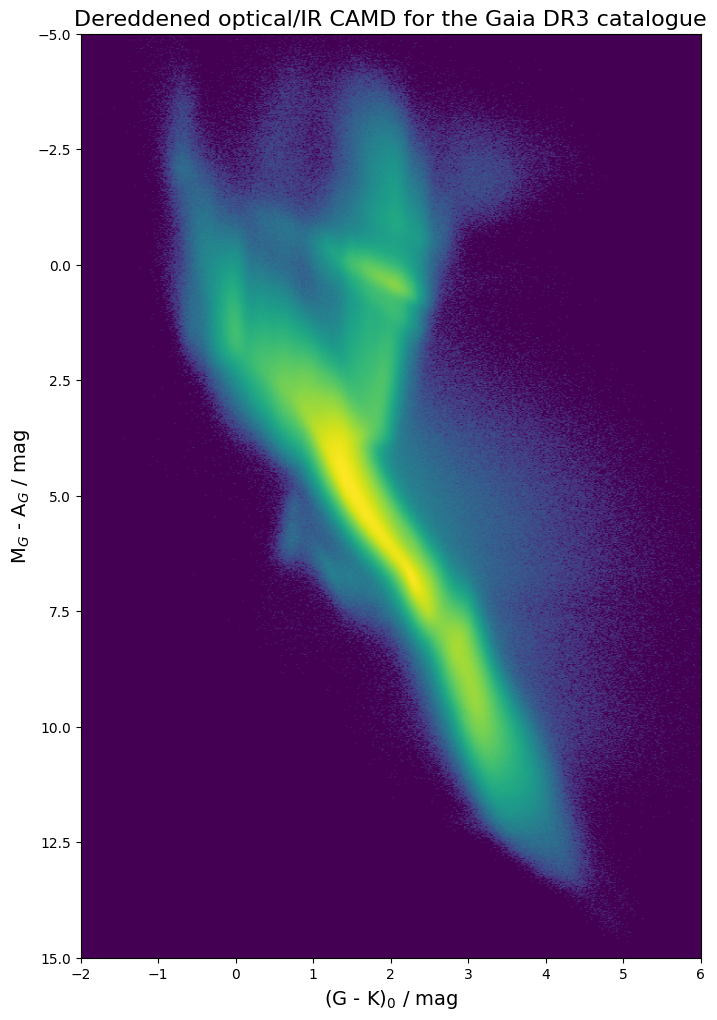

In [5]:
import matplotlib.pyplot as plot

# create a sparse array object for the results (only those elements with non-zero counts are in the results set)
from scipy.sparse import coo_matrix # renamed coo_array in later versions of scipy
# https://docs.scipy.org/doc/scipy-1.6.3/reference/generated/scipy.sparse.coo_matrix.html#scipy.sparse.coo_matrix
sparse_data = coo_matrix((np.log(pdf['count_in_pixel']), (pdf['yidx'], pdf['xidx'])), shape = (ymax_idx, xmax_idx))
# ... use logged counts to enhance low-level features in the CAMD

# expand into a dense array in order to plot as an image with imshow
dense_data = sparse_data.todense()

# do the plot
plot.figure(0, figsize = (8.0, 12.0))
plot.title('Dereddened optical/IR CAMD for the Gaia DR3 catalogue', fontsize = 16)
plot.xlabel('(G - K)$_0$ / mag', fontsize = 14)
plot.ylabel('M$_G$ - A$_G$ / mag', fontsize = 14)
plot.imshow(dense_data, aspect = 'auto', 
    extent = [bluest_colour, bluest_colour + xmax_idx * mag_resolution, brightest_abs_mag + ymax_idx * mag_resolution, brightest_abs_mag])

* [Gaia data release cross-matches](https://gea.esac.esa.int/archive/documentation/GDR3/Catalogue_consolidation/chap_crossmatch/)
* [2MASS PSC](https://irsa.ipac.caltech.edu/data/2MASS/docs/releases/allsky/doc/sec2_2a.html "2MASS point-source catalogue column details")
* [ALLWISE](https://wise2.ipac.caltech.edu/docs/release/allwise/expsup/sec2_1a.html "ALLWISE catalogue column details")
* [PS1 OTMO](https://outerspace.stsci.edu/display/PANSTARRS/PS1+MeanObjectView+table+fields "PS1 DR1 object-thin object-mean catalogue column details") (note that column names follow the Gaia archive convention of all lower-case with underscore separators rather than the original CamelCase)
